In [83]:
import numpy as np
import pandas as pd
import plotly.express as px

In [84]:
df = pd.read_csv('Used Cars Prices.csv')
df

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6014,Maruti Swift VDI,Delhi,2014,27365,Diesel,Manual,First,28.4 kmpl,1248 CC,74 bhp,5.0,7.88 Lakh,4.75
6015,Hyundai Xcent 1.1 CRDi S,Jaipur,2015,100000,Diesel,Manual,First,24.4 kmpl,1120 CC,71 bhp,5.0,NaN,4.00
6016,Mahindra Xylo D4 BSIV,Jaipur,2012,55000,Diesel,Manual,Second,14.0 kmpl,2498 CC,112 bhp,8.0,NaN,2.90
6017,Maruti Wagon R VXI,Kolkata,2013,46000,Petrol,Manual,First,18.9 kmpl,998 CC,67.1 bhp,5.0,NaN,2.65


In [85]:
df.to_parquet('Used Cars Prices.parquet')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6019 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  
 3   Kilometers_Driven  6019 non-null   int64  
 4   Fuel_Type          6019 non-null   object 
 5   Transmission       6019 non-null   object 
 6   Owner_Type         6019 non-null   object 
 7   Mileage            6017 non-null   object 
 8   Engine             5983 non-null   object 
 9   Power              5983 non-null   object 
 10  Seats              5977 non-null   float64
 11  New_Price          824 non-null    object 
 12  Price              6019 non-null   float64
dtypes: float64(2), int64(2), object(9)
memory usage: 611.4+ KB


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.describe().round(2)

,Year,Kilometers_Driven,Seats,Price
count,6019.00,6019.00,5977.00,6019.00
mean,2013.36,58738.38,5.28,9.48
std,3.27,91268.84,0.81,11.19
min,1998.00,171.00,0.00,0.44
25%,2011.00,34000.00,5.00,3.50
50%,2014.00,53000.00,5.00,5.64
75%,2016.00,73000.00,5.00,9.95
max,2019.00,6500000.00,10.00,160.00


In [6]:
df.describe(include= ['object'])

,Name,Location,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,New_Price
count,6019,6019,6019,6019,6019,6017,5983,5983,824
unique,1876,11,5,2,4,442,146,372,540
top,Mahindra XUV500 W8 2WD,Mumbai,Diesel,Manual,First,18.9 kmpl,1197 CC,74 bhp,95.13 Lakh
freq,49,790,3205,4299,4929,172,606,235,6


In [7]:
df.isna().sum()

Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                  36
Seats                  42
New_Price            5195
Price                   0
dtype: int64

In [8]:
df.isna().mean().round(4) * 100

Name                  0.00
Location              0.00
Year                  0.00
Kilometers_Driven     0.00
Fuel_Type             0.00
Transmission          0.00
Owner_Type            0.00
Mileage               0.03
Engine                0.60
Power                 0.60
Seats                 0.70
New_Price            86.31
Price                 0.00
dtype: float64

## Data Cleaning

In [9]:
# Drop missing values
df.dropna(subset=['Mileage', 'Engine', 'Power'])

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6014,Maruti Swift VDI,Delhi,2014,27365,Diesel,Manual,First,28.4 kmpl,1248 CC,74 bhp,5.0,7.88 Lakh,4.75
6015,Hyundai Xcent 1.1 CRDi S,Jaipur,2015,100000,Diesel,Manual,First,24.4 kmpl,1120 CC,71 bhp,5.0,NaN,4.00
6016,Mahindra Xylo D4 BSIV,Jaipur,2012,55000,Diesel,Manual,Second,14.0 kmpl,2498 CC,112 bhp,8.0,NaN,2.90
6017,Maruti Wagon R VXI,Kolkata,2013,46000,Petrol,Manual,First,18.9 kmpl,998 CC,67.1 bhp,5.0,NaN,2.65


In [10]:
5981 / df.shape[0]

0.9936866589134408

In [11]:
df.dropna(subset=['Mileage', 'Engine', 'Power'], inplace= True)

In [12]:
# Check seats with 0 values
df[df['Seats'] == 0]

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
3999,Audi A4 3.2 FSI Tiptronic Quattro,Hyderabad,2012,125000,Petrol,Automatic,First,10.5 kmpl,3197 CC,null bhp,0.0,NaN,18.0


In [13]:
df.loc[3999, 'Seats'] = 5

In [14]:
df[df['Seats'] == 0]

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price


In [15]:
df.loc[3999, 'Seats']

np.float64(5.0)

In [16]:
df.isna().mean().round(4) * 100

Name                  0.00
Location              0.00
Year                  0.00
Kilometers_Driven     0.00
Fuel_Type             0.00
Transmission          0.00
Owner_Type            0.00
Mileage               0.00
Engine                0.00
Power                 0.00
Seats                 0.10
New_Price            86.24
Price                 0.00
dtype: float64

In [17]:
df.dropna(subset= 'Seats', inplace= True)

In [18]:
df.reset_index(drop= True, inplace= True)

In [19]:
# Check Kilometers driven column
px.histogram(data_frame= df, x= 'Kilometers_Driven')

In [20]:
px.box(data_frame= df, x= 'Kilometers_Driven')

In [21]:
df[df['Kilometers_Driven'] == 6500000.00]

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
2314,BMW X5 xDrive 30d M Sport,Chennai,2017,6500000,Diesel,Automatic,First,15.97 kmpl,2993 CC,258 bhp,5.0,NaN,65.0


In [22]:
drop_index = df[df['Kilometers_Driven'] == 6500000.00].index
drop_index

Index([2314], dtype='int64')

In [23]:
df.drop(drop_index, axis= 0, inplace= True)

In [24]:
df.reset_index(drop= True, inplace= True)

In [25]:
# Drop unnecessary columns
df.drop('New_Price', axis= 1, inplace= True)

### In deptch check for categorical columns

In [26]:
cat_cols = df.select_dtypes(include= 'object').columns
cat_cols

Index(['Name', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type',
       'Mileage', 'Engine', 'Power'],
      dtype='object')

In [27]:
for col in cat_cols:
    print(col)
    print(df[col].nunique())
    print(df[col].unique())
    print('-' * 100)

Name
1855
['Maruti Wagon R LXI CNG' 'Hyundai Creta 1.6 CRDi SX Option'
 'Honda Jazz V' ... 'Volkswagen Polo IPL II 1.2 Petrol Highline'
 'Tata Bolt Revotron XT' 'Mahindra Xylo D4 BSIV']
----------------------------------------------------------------------------------------------------
Location
11
['Mumbai' 'Pune' 'Chennai' 'Coimbatore' 'Hyderabad' 'Jaipur' 'Kochi'
 'Kolkata' 'Delhi' 'Bangalore' 'Ahmedabad']
----------------------------------------------------------------------------------------------------
Fuel_Type
4
['CNG' 'Diesel' 'Petrol' 'LPG']
----------------------------------------------------------------------------------------------------
Transmission
2
['Manual' 'Automatic']
----------------------------------------------------------------------------------------------------
Owner_Type
4
['First' 'Second' 'Fourth & Above' 'Third']
----------------------------------------------------------------------------------------------------
Mileage
442
['26.6 km/kg' '19.67 kmpl' '18.2 

In [28]:
df[df['Power'] == 'null bhp']

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
76,Ford Fiesta 1.4 SXi TDCi,Jaipur,2008,111111,Diesel,Manual,First,17.8 kmpl,1399 CC,null bhp,5.0,2.00
79,Hyundai Santro Xing XL,Hyderabad,2005,87591,Petrol,Manual,First,0.0 kmpl,1086 CC,null bhp,5.0,1.30
89,Hyundai Santro Xing XO,Hyderabad,2007,73745,Petrol,Manual,First,17.0 kmpl,1086 CC,null bhp,5.0,2.10
120,Hyundai Santro Xing XL eRLX Euro III,Mumbai,2005,102000,Petrol,Manual,Second,17.0 kmpl,1086 CC,null bhp,5.0,0.85
143,Hyundai Santro Xing XO eRLX Euro II,Kochi,2008,80759,Petrol,Manual,Third,17.0 kmpl,1086 CC,null bhp,5.0,1.67
...,...,...,...,...,...,...,...,...,...,...,...,...
5817,Hyundai Santro Xing XO,Chennai,2007,79000,Petrol,Manual,First,17.0 kmpl,1086 CC,null bhp,5.0,1.85
5829,Hyundai Santro Xing XO eRLX Euro II,Pune,2006,47200,Petrol,Manual,Second,17.0 kmpl,1086 CC,null bhp,5.0,1.20
5880,Skoda Laura Classic 1.8 TSI,Pune,2010,85000,Petrol,Manual,First,17.5 kmpl,1798 CC,null bhp,5.0,2.85
5898,Mahindra Jeep MM 540 DP,Chennai,2002,75000,Diesel,Manual,First,0.0 kmpl,2112 CC,null bhp,6.0,1.70


In [29]:
drop_indices = df[df['Power'] == 'null bhp'].index
drop_indices

Index([  76,   79,   89,  120,  143,  225,  242,  259,  304,  305,
       ...
       5485, 5489, 5603, 5711, 5715, 5817, 5829, 5880, 5898, 5940],
      dtype='int64', length=103)

In [30]:
df.drop(drop_indices, axis= 0, inplace= True)

df.reset_index(inplace= True, drop= True)

In [31]:
# Convert Mileage to Float

df['Mileage']

0       26.6 km/kg
1       19.67 kmpl
2        18.2 kmpl
3       20.77 kmpl
4        15.2 kmpl
           ...    
5866     28.4 kmpl
5867     24.4 kmpl
5868     14.0 kmpl
5869     18.9 kmpl
5870    25.44 kmpl
Name: Mileage, Length: 5871, dtype: object

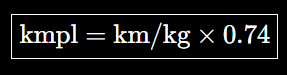

In [32]:
def clean_mileage(x):

    if 'kmpl' in x:
        return float(x.replace(' kmpl', ''))

    elif 'km/kg' in x:
        return float(x.replace(' km/kg', '')) * 0.74

    else:
        return x

df['Mileage'] = df['Mileage'].apply(clean_mileage)
df['Mileage']

0       19.684
1       19.670
2       18.200
3       20.770
4       15.200
         ...  
5866    28.400
5867    24.400
5868    14.000
5869    18.900
5870    25.440
Name: Mileage, Length: 5871, dtype: float64

In [33]:
df['Engine'] = df['Engine'].str.replace(' CC', '').astype('float')
df['Engine']

0        998.0
1       1582.0
2       1199.0
3       1248.0
4       1968.0
         ...  
5866    1248.0
5867    1120.0
5868    2498.0
5869     998.0
5870     936.0
Name: Engine, Length: 5871, dtype: float64

In [34]:
df['Power'] = df['Power'].apply(lambda x : x.replace(' bhp', '')).astype('float')
df['Power']

0        58.16
1       126.20
2        88.70
3        88.76
4       140.80
         ...  
5866     74.00
5867     71.00
5868    112.00
5869     67.10
5870     57.60
Name: Power, Length: 5871, dtype: float64

### In depth check for numerical columns

In [35]:
num_cols = df.select_dtypes(include= 'number').columns
num_cols

Index(['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats',
       'Price'],
      dtype='object')

In [36]:
for col in num_cols:

    px.histogram(data_frame= df, x= col, title= col).show()
    px.box(data_frame= df, x= col, title= col).show()

In [37]:
df.head()

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,19.684,998.0,58.16,5.0,1.75
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.670,1582.0,126.20,5.0,12.50
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.200,1199.0,88.70,5.0,4.50
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.770,1248.0,88.76,7.0,6.00
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.200,1968.0,140.80,5.0,17.74


In [38]:
df['Name'].value_counts().tail(50)

Name
Mercedes-Benz GLA Class 200 d Style                        1
Toyota Camry W2 (AT)                                       1
Toyota Etios VD SP                                         1
Skoda Rapid Ultima 1.6 MPI Ambition Plus                   1
Chevrolet Optra 1.6 LT Royale                              1
Hyundai Elite i20 Diesel Asta Option                       1
Toyota Etios 1.4 VXD                                       1
Tata Tigor XE Diesel                                       1
Hyundai i20 1.4 Asta Optional With Sunroof                 1
Maruti Wagon R ZXI AMT 1.2                                 1
Nissan Sunny XV D                                          1
Porsche Panamera 2010 2013 Diesel                          1
Hyundai Verna 1.6 i ABS                                    1
Volvo XC60 D4 SUMMUM                                       1
Honda Mobilio RS Option i DTEC                             1
Renault Duster 110PS Diesel RxZ AWD                        1
Honda CR-V Petrol 2

### Feature Engineering

In [39]:
'Ford Figo Diesel EXI Option'.split()[0]

'Ford'

In [40]:
df['Brand'] = df['Name'].str.split().str[0]
df['Brand']

0          Maruti
1         Hyundai
2           Honda
3          Maruti
4            Audi
          ...    
5866       Maruti
5867      Hyundai
5868     Mahindra
5869       Maruti
5870    Chevrolet
Name: Brand, Length: 5871, dtype: object

In [41]:
df['Brand'].value_counts()

Brand
Maruti           1175
Hyundai          1058
Honda             600
Toyota            394
Mercedes-Benz     316
Volkswagen        314
Ford              294
Mahindra          268
BMW               261
Audi              235
Tata              183
Skoda             172
Renault           145
Chevrolet         120
Nissan             89
Land               57
Jaguar             40
Mitsubishi         27
Mini               26
Fiat               23
Volvo              21
Porsche            16
Jeep               15
Datsun             13
Force               3
ISUZU               2
Isuzu               1
Ambassador          1
Bentley             1
Lamborghini         1
Name: count, dtype: int64

In [42]:
# Remove low frequent categories (1)

def clean_isuzu(x):

    if 'ISUZU' in x:
        return 'Isuzu'

    else:
        return x

df['Brand'] = df['Brand'].apply(clean_isuzu)
df['Brand']

0          Maruti
1         Hyundai
2           Honda
3          Maruti
4            Audi
          ...    
5866       Maruti
5867      Hyundai
5868     Mahindra
5869       Maruti
5870    Chevrolet
Name: Brand, Length: 5871, dtype: object

In [43]:
# Drop Name column
df.drop('Name', axis= 1, inplace = True)

In [44]:
df.to_csv('cleaned_df.csv', index= False)

## Data Preprocessing for ML

### 1) Split Data into Input and Output

In [79]:
x = df.drop('Price', axis= 1)
y = df['Price']

### 2) Create Numerical Pipelines

In [80]:
num_cols = x.select_dtypes(include= 'number').columns
num_cols

Index(['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats'], dtype='object')

In [81]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

num_pipeline = Pipeline(steps= [ ('Scaling', scaler) ])
num_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Scaling', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"with_centering with_centering: bool, default=TrueIf `True`, center the data before scaling.This will cause :meth:`transform` to raise an exception when attemptedon sparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_scaling with_scaling: bool, default=TrueIf `True`, scale the data to interquartile range.",True
,"quantile_range quantile_range: tuple (q_min, q_max), 0.0 < q_min < q_max < 100.0, default=(25.0, 75.0)Quantile range used to calculate `scale_`. By default this is equal tothe IQR, i.e., `q_min` is the first quantile and `q_max` is the thirdquantile... versionadded:: 0.18","(25.0, ...)"
,"copy copy: bool, default=TrueIf `False`, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"unit_variance unit_variance: bool, default=FalseIf `True`, scale data so that normally distributed features have avariance of 1. In general, if the difference between the x-values of`q_max` and `q_min` for a standard normal distribution is greaterthan 1, the dataset will be scaled down. If less than 1, the datasetwill be scaled up... versionadded:: 0.24",False


### 3) Create Categorical Pipelines

3.1 OHE Pipeline

In [48]:
ohe_cols = ['Fuel_Type', 'Transmission']
ohe_cols

['Fuel_Type', 'Transmission']

In [49]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output= False, drop= 'first')

ohe_pipeline = Pipeline(steps= [ ('OHE', ohe) ])
ohe_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('OHE', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",'first'
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='e

3.2 BE Pipeline

In [50]:
be_cols = ['Location', 'Brand']
be_cols

['Location', 'Brand']

In [51]:
from category_encoders import BinaryEncoder

be = BinaryEncoder()

be_pipeline = Pipeline(steps= [ ('BE', be) ])
be_pipeline

c:\Anaconda\envs\DA\Lib\site-packages\sklearn\externals\_numpydoc\docscrape.py:420: UserWarning: Unknown section Example
  self[section] = content


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('BE', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,verbose,0
,cols,None
,mapping,None
,drop_invariant,False
,return_df,True
,base,2
,handle_unknown,'value'


3.3 Ordinal Pipeline

In [52]:
ord_cols = ['Owner_Type']
ord_cols

['Owner_Type']

In [53]:
from sklearn.preprocessing import OrdinalEncoder

ord = OrdinalEncoder(categories= [ ['Fourth & Above', 'Third', 'Second', 'First'] ])

ord_pipeline = Pipeline(steps= [ ('Ord', ord) ])
ord_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Ord', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute.","[['Fourth & Above', 'Third', ...]]"
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'use_encoded_value'}, default='error'When set to 'error' an error will be raised in case an unknowncategorical feature is present during transform. When set to'use_encoded_value', the encoded value of unknown categories will beset to the value given for the parameter `unknown_value`. In:meth:`inverse_transform`, an unknown category will be denoted as None... versionadded:: 0.24",'error'
,"unknown_value unknown_value: int or np.nan, default=NoneWhen the parameter handle_unknown is set to 'use_encoded_value', thisparameter is required and will set the encoded value of unknowncategories. It has to be distinct from the values used to encode any ofthe categories in `fit`. If set to np.nan, the `dtype` parameter mustbe a float dtype... versionadded:: 0.24",None
,"encoded_missing_value encoded_missing_value: int or np.nan, default=np.nanEncoded value of missing categories. If set to `np.nan`, then the `dtype`parameter must be a float dtype... versionadded:: 1.1",nan
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.3 Read more in the :ref:`User Guide <encoder_infrequent_categories>`.",None
,"max_categories max_categories: int, default=NoneSpecifies an upper limit to the number of output categories for each inputfeature when co

### 4) Assign each column to corresponding Pipeline

In [54]:
from sklearn.compose import ColumnTransformer

preprocessing = ColumnTransformer(transformers= [
    ('Num Pipeline', num_pipeline, num_cols),
    ('OHE Pipeline', ohe_pipeline, ohe_cols),
    ('BE Pipeline', be_pipeline, be_cols),
    ('Ordinal Pipeline', ord_pipeline, ord_cols)
], remainder= 'passthrough')                        # Only add passthrough if you have columns with no corrsponding pipeline (Added here as example only)

preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Num Pipeline', ...), ('OHE Pipeline', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transform

In [55]:
from sklearn.linear_model import LinearRegression

le = LinearRegression()

model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing), ('Model', le) ])
model_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Num Pipeline', ...), ('OHE Pipeline', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_thre

# Select Best Model

In [56]:
from sklearn.linear_model import LinearRegression, SGDRegressor, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_validate

models = [
    ('Linear Regression', LinearRegression()),
    ('SGD Regressor', SGDRegressor(random_state= 42)),
    ('Lasso', Lasso(random_state= 42)),
    ('Ridge', Ridge(random_state= 42)),
    ('KNN Regressor', KNeighborsRegressor()),
    ('SVR', SVR()),
    ('Decision Tree Regressor', DecisionTreeRegressor(random_state= 42)),
    ('Random Forest Regressor', RandomForestRegressor(random_state= 42)),
    ('XGB Regressor', XGBRegressor(random_state= 42))
]

for model in models:

    

    model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing), ('Model', model[1]) ])

    cv_scores = cross_validate(model_pipeline, x, y, cv= 5, scoring= 'r2', return_train_score= True)

    print(model[0])
    print('Train Score: ', round(cv_scores['train_score'].mean() * 100, 3))
    print('Test Score: ', round(cv_scores['test_score'].mean() * 100, 3))
    print('\n', '-' * 100, '\n')

Linear Regression
Train Score:  71.917
Test Score:  71.522

 ---------------------------------------------------------------------------------------------------- 

SGD Regressor
Train Score:  71.708
Test Score:  71.304

 ---------------------------------------------------------------------------------------------------- 

Lasso
Train Score:  65.687
Test Score:  65.452

 ---------------------------------------------------------------------------------------------------- 

Ridge
Train Score:  71.917
Test Score:  71.523

 ---------------------------------------------------------------------------------------------------- 

KNN Regressor
Train Score:  91.099
Test Score:  84.103

 ---------------------------------------------------------------------------------------------------- 

SVR
Train Score:  79.196
Test Score:  78.405

 ---------------------------------------------------------------------------------------------------- 

Decision Tree Regressor
Train Score:  100.0
Test Score:  76.74

### Adding Polynomial to Pipeline (with Linear Regression)

In [57]:
from sklearn.linear_model import LinearRegression, SGDRegressor, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import PolynomialFeatures

models = [
    ('Linear Regression', LinearRegression()),
    ('SGD Regressor', SGDRegressor(random_state= 42)),
    ('Lasso', Lasso(random_state= 42)),
    ('Ridge', Ridge(random_state= 42)),
    ('KNN Regressor', KNeighborsRegressor()),
    ('SVR', SVR()),
    ('Decision Tree Regressor', DecisionTreeRegressor(random_state= 42)),
    ('Random Forest Regressor', RandomForestRegressor(random_state= 42)),
    ('XGB Regressor', XGBRegressor(random_state= 42)),
    ('Polynomial Regression', PolynomialFeatures())
]

for model in models:

    model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing), ('Model', model[1]) ])

    if model[0] == 'Polynomial Regression':
        model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing),
                                           ('Polynomial Features', model[1]),
                                           ('Model', LinearRegression()) ])

    cv_scores = cross_validate(model_pipeline, x, y, cv= 5, scoring= 'r2', return_train_score= True)

    print(model[0])
    print('Train Score: ', round(cv_scores['train_score'].mean() * 100, 3))
    print('Test Score: ', round(cv_scores['test_score'].mean() * 100, 3))
    print('\n', '-' * 100, '\n')

Linear Regression
Train Score:  71.917
Test Score:  71.522

 ---------------------------------------------------------------------------------------------------- 

SGD Regressor
Train Score:  71.708
Test Score:  71.304

 ---------------------------------------------------------------------------------------------------- 

Lasso
Train Score:  65.687
Test Score:  65.452

 ---------------------------------------------------------------------------------------------------- 

Ridge
Train Score:  71.917
Test Score:  71.523

 ---------------------------------------------------------------------------------------------------- 

KNN Regressor
Train Score:  91.099
Test Score:  84.103

 ---------------------------------------------------------------------------------------------------- 

SVR
Train Score:  79.196
Test Score:  78.405

 ---------------------------------------------------------------------------------------------------- 

Decision Tree Regressor
Train Score:  100.0
Test Score:  76.74

### Adding Polynomial to Pipeline (with Lasso)

In [58]:
from sklearn.linear_model import LinearRegression, SGDRegressor, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import PolynomialFeatures

models = [
    # ('Linear Regression', LinearRegression()),
    # ('SGD Regressor', SGDRegressor(random_state= 42)),
    # ('Lasso', Lasso(random_state= 42)),
    # ('Ridge', Ridge(random_state= 42)),
    ('KNN Regressor', KNeighborsRegressor()),
    # ('SVR', SVR()),
    ('Decision Tree Regressor', DecisionTreeRegressor(random_state= 42)),
    ('Random Forest Regressor', RandomForestRegressor(random_state= 42)),
    ('XGB Regressor', XGBRegressor(random_state= 42)),
    ('Polynomial Regression', PolynomialFeatures())
]

for model in models:

    model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing), ('Model', model[1]) ])

    if model[0] == 'Polynomial Regression':
        model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing),
                                           ('Polynomial Features', model[1]),
                                           ('Model', Lasso(random_state= 42)) ])

    cv_scores = cross_validate(model_pipeline, x, y, cv= 5, scoring= 'r2', return_train_score= True)

    print(model[0])
    print('Train Score: ', round(cv_scores['train_score'].mean() * 100, 3))
    print('Test Score: ', round(cv_scores['test_score'].mean() * 100, 3))
    print('\n', '-' * 100, '\n')

KNN Regressor
Train Score:  91.099
Test Score:  84.103

 ---------------------------------------------------------------------------------------------------- 

Decision Tree Regressor
Train Score:  100.0
Test Score:  76.745

 ---------------------------------------------------------------------------------------------------- 

Random Forest Regressor
Train Score:  98.485
Test Score:  86.308

 ---------------------------------------------------------------------------------------------------- 

XGB Regressor
Train Score:  99.65
Test Score:  87.714

 ---------------------------------------------------------------------------------------------------- 

Polynomial Regression
Train Score:  77.017
Test Score:  76.131

 ---------------------------------------------------------------------------------------------------- 



### Adding Polynomial to Pipeline (with Ridge)

In [59]:
from sklearn.linear_model import LinearRegression, SGDRegressor, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import PolynomialFeatures

models = [
    # ('Linear Regression', LinearRegression()),
    # ('SGD Regressor', SGDRegressor(random_state= 42)),
    # ('Lasso', Lasso(random_state= 42)),
    # ('Ridge', Ridge(random_state= 42)),
    ('KNN Regressor', KNeighborsRegressor()),
    # ('SVR', SVR()),
    ('Decision Tree Regressor', DecisionTreeRegressor(random_state= 42)),
    ('Random Forest Regressor', RandomForestRegressor(random_state= 42)),
    ('XGB Regressor', XGBRegressor(random_state= 42)),
    ('Polynomial Regression', PolynomialFeatures())
]

for model in models:

    model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing), ('Model', model[1]) ])

    if model[0] == 'Polynomial Regression':
        model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing),
                                           ('Polynomial Features', model[1]),
                                           ('Model', Ridge(random_state= 42)) ])

    cv_scores = cross_validate(model_pipeline, x, y, cv= 5, scoring= 'r2', return_train_score= True)

    print(model[0])
    print('Train Score: ', round(cv_scores['train_score'].mean() * 100, 3))
    print('Test Score: ', round(cv_scores['test_score'].mean() * 100, 3))
    print('\n', '-' * 100, '\n')

KNN Regressor
Train Score:  91.099
Test Score:  84.103

 ---------------------------------------------------------------------------------------------------- 

Decision Tree Regressor
Train Score:  100.0
Test Score:  76.745

 ---------------------------------------------------------------------------------------------------- 

Random Forest Regressor
Train Score:  98.485
Test Score:  86.308

 ---------------------------------------------------------------------------------------------------- 

XGB Regressor
Train Score:  99.65
Test Score:  87.714

 ---------------------------------------------------------------------------------------------------- 

Polynomial Regression
Train Score:  89.966
Test Score:  86.948

 ---------------------------------------------------------------------------------------------------- 



# TransformedTargetRegressor 

In [60]:
np.log1p(y)

0       1.011601
1       2.602690
2       1.704748
3       1.945910
4       2.930660
          ...   
5866    1.749200
5867    1.609438
5868    1.360977
5869    1.294727
5870    1.252763
Name: Price, Length: 5871, dtype: float64

In [61]:
np.expm1(np.log1p(y))

0        1.75
1       12.50
2        4.50
3        6.00
4       17.74
        ...  
5866     4.75
5867     4.00
5868     2.90
5869     2.65
5870     2.50
Name: Price, Length: 5871, dtype: float64

In [62]:
from sklearn.linear_model import LinearRegression, SGDRegressor, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import PolynomialFeatures
from sklearn.compose import TransformedTargetRegressor

models = [
    # ('Linear Regression', LinearRegression()),
    # ('SGD Regressor', SGDRegressor(random_state= 42)),
    # ('Lasso', Lasso(random_state= 42)),
    # ('Ridge', Ridge(random_state= 42)),
    ('KNN Regressor', KNeighborsRegressor()),
    # ('SVR', SVR()),
    ('Decision Tree Regressor', DecisionTreeRegressor(random_state= 42)),
    ('Random Forest Regressor', RandomForestRegressor(random_state= 42)),
    ('XGB Regressor', XGBRegressor(random_state= 42)),
    ('Polynomial Regression', PolynomialFeatures())
]

for model in models:

    model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing), ('Model', model[1]) ])

    if model[0] == 'Polynomial Regression':
        model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing),
                                           ('Polynomial Features', model[1]),
                                           ('Model', Ridge(random_state= 42)) ])

    transformed_pipline = TransformedTargetRegressor(
        regressor= model_pipeline,
        func= np.log1p,
        inverse_func= np.expm1
    )

    cv_scores = cross_validate(transformed_pipline, x, y, cv= 5, scoring= 'r2', return_train_score= True)

    print(model[0])
    print('Train Score: ', round(cv_scores['train_score'].mean() * 100, 3))
    print('Test Score: ', round(cv_scores['test_score'].mean() * 100, 3))
    print('\n', '-' * 100, '\n')

KNN Regressor
Train Score:  90.44
Test Score:  83.517

 ---------------------------------------------------------------------------------------------------- 

Decision Tree Regressor
Train Score:  100.0
Test Score:  71.731

 ---------------------------------------------------------------------------------------------------- 

Random Forest Regressor
Train Score:  98.052
Test Score:  83.766

 ---------------------------------------------------------------------------------------------------- 

XGB Regressor
Train Score:  99.28
Test Score:  85.281

 ---------------------------------------------------------------------------------------------------- 

Polynomial Regression
Train Score:  90.007
Test Score:  84.244

 ---------------------------------------------------------------------------------------------------- 



# Hyperparameter Tuning

In [63]:
model_pipeline = Pipeline(steps= [ ('Preprocessing', preprocessing),
                                   ('Polynomial Features', PolynomialFeatures()),
                                   ('Model', Ridge(random_state= 42)) ])
model_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Polynomial Features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Num Pipeline', ...), ('OHE Pipeline', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_th

In [64]:
from sklearn.model_selection import GridSearchCV

parma_grid ={
    'Model__alpha' : [1, 0.5, 0.1, 0.01],
    'Model__max_iter' : [None, 100, 500, 1000]
}
grid_search = GridSearchCV(
    estimator= model_pipeline,
    param_grid= parma_grid,
    scoring= ['r2', 'neg_mean_absolute_error'],
    cv= 5,
    n_jobs= -1,
    return_train_score= True,
    refit= 'r2'
)

grid_search.fit(x, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model__alpha': [1, 0.5, ...], 'Model__max_iter': [None, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['r2', 'neg_mean_absolute_error']"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_trai

In [65]:
grid_search.best_params_

{'Model__alpha': 1, 'Model__max_iter': None}

In [66]:
grid_search.best_score_

np.float64(0.8694796548257703)

In [67]:
grid_search.cv_results_

{'mean_fit_time': array([0.22583232, 0.13932509, 0.28418112, 0.17666135, 0.21285653,
        0.17542224, 0.1490922 , 0.16164641, 0.14935875, 0.14718556,
        0.1608429 , 0.15004973, 0.27409601, 0.16105151, 0.17893925,
        0.15609188]),
 'std_fit_time': array([0.04607365, 0.0050136 , 0.07026552, 0.03095131, 0.00823792,
        0.02550901, 0.01163011, 0.01306034, 0.00944299, 0.00542226,
        0.00842945, 0.0124799 , 0.09647651, 0.00666333, 0.01683668,
        0.02791994]),
 'mean_score_time': array([0.03619208, 0.03558769, 0.04981127, 0.06108632, 0.04756308,
        0.05193214, 0.0378943 , 0.03844767, 0.0379179 , 0.03482108,
        0.04271011, 0.05735044, 0.04576907, 0.03635287, 0.05937748,
        0.04447699]),
 'std_score_time': array([0.00400381, 0.00585814, 0.01099908, 0.01066436, 0.01127076,
        0.01150329, 0.00274534, 0.00271608, 0.00515169, 0.00258858,
        0.00736578, 0.02858494, 0.01700126, 0.00310221, 0.01534883,
        0.01627056]),
 'param_Model__alpha': mas

In [68]:
ridge_model = grid_search.best_estimator_
ridge_model.fit(x, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Polynomial Features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Location','Year','Kilometers_Driven',...,'Power','Seats','Brand']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Num Pipeline', ...), ('OHE Pipeline', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically

In [69]:
x.head(1)

,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Brand
0,Mumbai,2010,72000,CNG,Manual,First,19.684,998.0,58.16,5.0,Maruti


In [77]:
ridge_model.predict(x.head(1)).round(2)[0]

np.float64(2.35)

In [ ]:
#df = pd.read_csv('test.csv')

In [71]:
y

0        1.75
1       12.50
2        4.50
3        6.00
4       17.74
        ...  
5866     4.75
5867     4.00
5868     2.90
5869     2.65
5870     2.50
Name: Price, Length: 5871, dtype: float64

In [72]:
import joblib

joblib.dump(ridge_model, 'ridge_model.joblib')

['ridge_model.joblib']

In [74]:
# Save Inputs

joblib.dump(x.columns, 'Inputs.pkl')

['Inputs.pkl']

In [75]:
x.columns

Index(['Location', 'Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission',
       'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats', 'Brand'],
      dtype='object')

In [73]:
df.head()

,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price,Brand
0,Mumbai,2010,72000,CNG,Manual,First,19.684,998.0,58.16,5.0,1.75,Maruti
1,Pune,2015,41000,Diesel,Manual,First,19.670,1582.0,126.20,5.0,12.50,Hyundai
2,Chennai,2011,46000,Petrol,Manual,First,18.200,1199.0,88.70,5.0,4.50,Honda
3,Chennai,2012,87000,Diesel,Manual,First,20.770,1248.0,88.76,7.0,6.00,Maruti
4,Coimbatore,2013,40670,Diesel,Automatic,Second,15.200,1968.0,140.80,5.0,17.74,Audi


In [82]:
ridge_model.predict(x.head(10))

array([ 2.34700335,  9.34803862,  4.17872363,  6.39432021, 18.15987991,
        3.00726976,  4.82532831, 24.05796968,  5.03822889,  0.51820052])